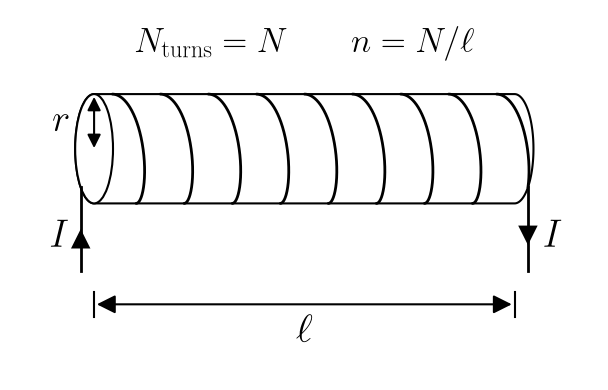

In [7]:
import numpy as np
import shutil
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse, FancyArrowPatch

# Generated by claude:
# https://claude.ai/share/94e5dfd7-1991-4e53-8698-fbcab51bc043

# ---- LaTeX rendering (falls back to Computer Modern mathtext if LaTeX is missing)
USE_LATEX = shutil.which("latex") is not None and shutil.which("dvipng") is not None
plt.rcParams.update({
    "text.usetex": USE_LATEX,
    "font.family": "serif",
    "mathtext.fontset": "cm",
    "font.serif": ["Computer Modern Roman", "DejaVu Serif"],
})

# ---- parameters -------------------------------------------------------------
N = 8            # approximate number of turns
L = 10.0         # coil length
R = 1.3          # coil radius
e = 0.45         # horizontal "perspective" offset of the end faces
x0 = 0.0         # left end position
t0 = 0.75 * np.pi                      # wire starts at the BACK (hidden), lower half
t1 = t0 + 2 * np.pi * N + 1.5 * np.pi  # wire ends at the FRONT, lower half
pitch = L / ((t1 - t0) / (2 * np.pi))
body_color = "white"
face_color = "white"

fig, ax = plt.subplots(figsize=(8, 4))
ax.set_aspect("equal")
ax.axis("off")

xl, xr = x0, x0 + L

# ---- opaque cylinder body (silhouette = two caps + top/bottom lines) --------
th_r = np.linspace(-np.pi / 2, np.pi / 2, 100)
th_l = np.linspace(np.pi / 2, 3 * np.pi / 2, 100)
px = np.concatenate([xr + e * np.cos(th_r), xl + e * np.cos(th_l)])
py = np.concatenate([R * np.sin(th_r), R * np.sin(th_l)])
ax.fill(px, py, fc=body_color, ec="k", lw=1.5, zorder=1)

# left end face
ax.add_patch(Ellipse((xl, 0), 2 * e, 2 * R, fc=face_color, ec="k", lw=1.5, zorder=2))

# ---- helix: only the front half is visible ----------------------------------
t = np.linspace(t0, t1, 5000)
x = x0 + pitch * (t - t0) / (2 * np.pi) + e * np.cos(t)
y = -R * np.sin(t)               # minus sign = handedness
front = np.cos(t) > 0

idx = np.flatnonzero(np.diff(front.astype(int)) != 0) + 1
for seg in np.split(np.arange(len(t)), idx):
    if front[seg[0]]:
        seg = np.append(seg, min(seg[-1] + 1, len(t) - 1))
        ax.plot(x[seg], y[seg], color="k", lw=2, solid_capstyle="round", zorder=3)

# ---- leads ------------------------------------------------------------------
lead_len = 1.6
ybot = -R - lead_len
ax.plot([x[0], x[0]], [y[0], ybot], "k", lw=2, zorder=3)      # emerges from behind
ax.plot([x[-1], x[-1]], [y[-1], ybot], "k", lw=2, zorder=3)   # leaves from the front

# current arrows, arrowheads centred on the straight part of each lead
ymid = (-R + ybot) / 2
h = 0.19   # half the arrowhead length (data units)
ax.add_patch(FancyArrowPatch((x[0], ymid - h), (x[0], ymid + h), arrowstyle="-|>",
                             mutation_scale=35, color="k", lw=0,
                             shrinkA=0, shrinkB=0, zorder=4))      # current in (up)
ax.add_patch(FancyArrowPatch((x[-1], ymid + h), (x[-1], ymid - h), arrowstyle="-|>",
                             mutation_scale=35, color="k", lw=0,
                             shrinkA=0, shrinkB=0, zorder=4))      # current out (down)
ax.text(x[0] - 0.35, ymid, r"$I$", color="k", fontsize=28, ha="right", va="center")
ax.text(x[-1] + 0.35, ymid, r"$I$", color="k", fontsize=28, ha="left", va="center")

# ---- radius marker ----------------------------------------------------------
ax.annotate("", xy=(xl, R), xytext=(xl, -0.05),
            arrowprops=dict(arrowstyle="<|-|>", mutation_scale=20, color="k", lw=1.5), annotation_clip=False)
ax.text(xl - 1.0, R / 2, r"$r$", color="k", fontsize=28, va="center")

# ---- length dimension -------------------------------------------------------
yd = ybot - 0.8
for xc in (xl, xr):
    ax.plot([xc, xc], [yd - 0.3, yd + 0.3], "k", lw=1.5)
ax.annotate("", xy=(xr, yd), xytext=(xl, yd), arrowprops=dict(arrowstyle="<|-|>", mutation_scale=28, lw=1.5, color="k"))
ax.text((xl + xr) / 2, yd - 0.9, r"$\ell$", ha="center", fontsize=30)

# ---- title / formula --------------------------------------------------------
ax.text((xl + xr) / 2, R + 1.0, r"$N_{\mathrm{turns}} = N \qquad n = N/\ell$",
        ha="center", fontsize=25)

ax.set_xlim(xl - 2, xr + 2)
ax.set_ylim(yd - 1.8, R + 2)
plt.tight_layout()
plt.savefig("solenoid_schematic.svg", dpi=300)
plt.show()